In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\limli\Inti Folder\FYP\ai4i2020.csv")

In [3]:
df = pd.read_csv(r"C:\Users\limli\Inti Folder\FYP\ai4i2020.csv")
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [5]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [6]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [7]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [8]:
df["Machine failure"].value_counts(normalize=True)*100

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

In [9]:
df.duplicated().sum()

0

In [10]:
df.drop_duplicates(inplace=True)

In [11]:
df.columns
df.rename(columns={
    "Rotational speed [rpm]":"rpm",
    'Air temperature [K]': 'air_temp',
    'Process temperature [K]': 'process_temp',
    "Torque [Nm]":"torque",
    "Tool wear [min]":"tool_wear",
    "Machine failure":"failure"
}, inplace=True)

In [12]:
df.drop(columns=['UDI', 'Product ID'], inplace=True)

In [13]:
print(df.columns)

Index(['Type', 'air_temp', 'process_temp', 'rpm', 'torque', 'tool_wear',
       'failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'],
      dtype='object')


In [14]:
df["Type"] = df["Type"].map({"L":0,"M":1,"H":2})

In [15]:
import sqlite3
conn = sqlite3.connect("machine_monitor.db")
df.to_sql("machine_data", conn, if_exists="replace", index=False)

10000

In [16]:
# --- Group 1: 物理意义特征 ---

# 1. 温差（HDF 的核心触发条件）
df['temp_diff'] = df['process_temp'] - df['air_temp']

# 2. 功率 Power = Torque × Angular velocity
df['power'] = df['torque'] * (df['rpm'] * 2 * np.pi / 60)

# 3. 刀具磨损 × 扭矩（OSF 触发条件）
df['tool_torque'] = df['tool_wear'] * df['torque']

# 4. 刀具磨损指数（归一化到 0~1）
df['tool_wear_index'] = df['tool_wear'] / df['tool_wear'].max()

# 5. 转速与扭矩比值
df['rpm_torque_ratio'] = df['rpm'] / df['torque']

In [17]:
# --- Group 2: 滚动统计特征（模拟实时监控）---

window = 10

df['rpm_rolling_mean']       = df['rpm'].rolling(window).mean()
df['rpm_rolling_std']        = df['rpm'].rolling(window).std()
df['torque_rolling_mean']    = df['torque'].rolling(window).mean()
df['torque_rolling_std']     = df['torque'].rolling(window).std()
df['tool_wear_rolling_mean'] = df['tool_wear'].rolling(window).mean()

# 填补前 9 行的 NaN
df.bfill(inplace=True)

In [18]:
# --- Group 3: 风险阈值 Flag ---

# HDF 条件：temp_diff < 8.6 AND rpm < 1380
df['hdf_risk'] = ((df['temp_diff'] < 8.6) & (df['rpm'] < 1380)).astype(int)

# PWF 条件：power < 3500 或 > 9000
df['pwf_risk'] = ((df['power'] < 3500) | (df['power'] > 9000)).astype(int)

# OSF 条件：tool_torque > 11000（L type），用通用阈值
df['osf_risk'] = (df['tool_torque'] > 11000).astype(int)


In [19]:
# --- 确认新特征 ---
print("New shape:", df.shape)
print("\nNew columns added:")
new_cols = ['temp_diff', 'power', 'tool_torque', 'tool_wear_index',
            'rpm_torque_ratio', 'rpm_rolling_mean', 'rpm_rolling_std',
            'torque_rolling_mean', 'torque_rolling_std',
            'tool_wear_rolling_mean', 'hdf_risk', 'pwf_risk', 'osf_risk']
print(df[new_cols].describe())

New shape: (10000, 25)

New columns added:
          temp_diff         power   tool_torque  tool_wear_index  \
count  10000.000000  10000.000000  10000.000000     10000.000000   
mean      10.000630   6279.744953   4314.664550         0.426684   
std        1.001094   1067.418295   2826.567692         0.251597   
min        7.600000   1148.440610      0.000000         0.000000   
25%        9.300000   5561.184484   1963.650000         0.209486   
50%        9.800000   6271.027344   4012.950000         0.426877   
75%       11.000000   7003.002724   6279.000000         0.640316   
max       12.100000  10469.923005  16497.000000         1.000000   

       rpm_torque_ratio  rpm_rolling_mean  rpm_rolling_std  \
count      10000.000000      10000.000000     10000.000000   
mean          43.167216       1538.784870       164.429926   
std           25.053907         57.682774        70.566117   
min           15.665796       1364.300000        30.945113   
25%           30.482987       1498

In [20]:
# --- Group 4：Interaction Features ---

df['rpm_toolwear'] = df['rpm'] * df['tool_wear']
df['temp_torque'] = df['temp_diff'] * df['torque']
df['power_toolwear'] = df['power'] * df['tool_wear']

In [21]:
# --- Group 5：Trend Detection ---

df['rpm_change'] = df['rpm'].diff()
df['torque_change'] = df['torque'].diff()
df['wear_change'] = df['tool_wear'].diff()
df.fillna(0, inplace=True)

In [22]:
# --- Remaining Useful Life proxy ---

df['wear_remaining'] = df['tool_wear'].max() - df['tool_wear']

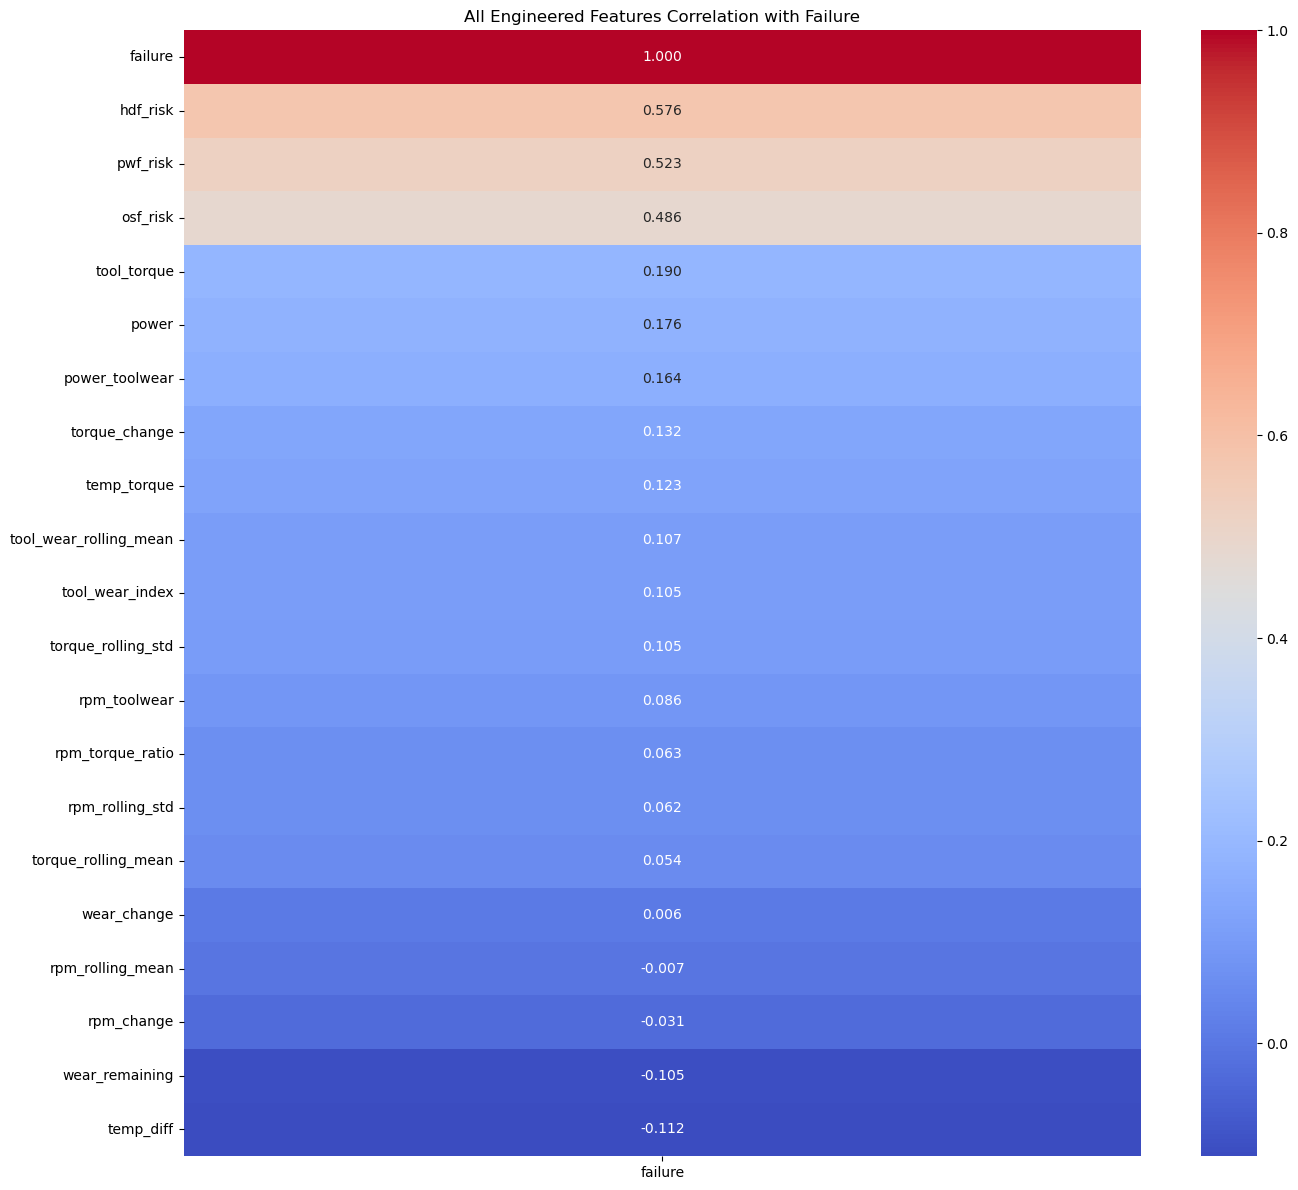

In [23]:
# 更新 new_cols 包含所有 engineered features
new_cols = [
    # Group 1-3 (原有)
    'temp_diff', 'power', 'tool_torque', 'tool_wear_index',
    'rpm_torque_ratio', 'rpm_rolling_mean', 'rpm_rolling_std',
    'torque_rolling_mean', 'torque_rolling_std', 'tool_wear_rolling_mean',
    'hdf_risk', 'pwf_risk', 'osf_risk',
    # Group 4 (Interaction)
    'rpm_toolwear', 'temp_torque', 'power_toolwear',
    # Group 5 (变化率)
    'rpm_change', 'torque_change', 'wear_change',
    # Group 7 (RUL)
    'wear_remaining'
]

# 重新画
plt.figure(figsize=(14, 12))
corr = df[new_cols + ['failure']].corr()
sns.heatmap(corr[['failure']].sort_values('failure', ascending=False),
            annot=True, cmap='coolwarm', fmt='.3f')
plt.title('All Engineered Features Correlation with Failure')
plt.tight_layout()
plt.show()

In [24]:
# 更新 SQLite
conn = sqlite3.connect("machine_monitor.db")
df.to_sql("machine_data", conn, if_exists="replace", index=False)
print("Phase 2 Final Done.")
print(f"Total features: {df.shape[1]}")
print(df.columns.tolist())

Phase 2 Final Done.
Total features: 32
['Type', 'air_temp', 'process_temp', 'rpm', 'torque', 'tool_wear', 'failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF', 'temp_diff', 'power', 'tool_torque', 'tool_wear_index', 'rpm_torque_ratio', 'rpm_rolling_mean', 'rpm_rolling_std', 'torque_rolling_mean', 'torque_rolling_std', 'tool_wear_rolling_mean', 'hdf_risk', 'pwf_risk', 'osf_risk', 'rpm_toolwear', 'temp_torque', 'power_toolwear', 'rpm_change', 'torque_change', 'wear_change', 'wear_remaining']


In [25]:
from scipy import stats
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report

# 定义用于异常检测的特征（排除所有 label 和 failure mode 列）
anomaly_features = [
    'air_temp', 'process_temp', 'rpm', 'torque', 'tool_wear',
    'temp_diff', 'power', 'tool_torque', 'tool_wear_index',
    'rpm_torque_ratio', 'rpm_rolling_mean', 'rpm_rolling_std',
    'torque_rolling_mean', 'torque_rolling_std', 'tool_wear_rolling_mean',
    'rpm_toolwear', 'temp_torque', 'power_toolwear',
    'rpm_change', 'torque_change', 'wear_change', 'wear_remaining'
]

# ============================================
# METHOD 1 — Z-SCORE
# ============================================
z_scores = np.abs(stats.zscore(df[anomaly_features]))
df['zscore_anomaly'] = (z_scores > 3).any(axis=1).astype(int)

print("Z-Score Anomalies detected:", df['zscore_anomaly'].sum())
print("\nCross-tab:")
print(pd.crosstab(df['zscore_anomaly'], df['failure'],
                  rownames=['Anomaly'], colnames=['Failure']))

# ============================================
# METHOD 2 — ISOLATION FOREST
# ============================================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[anomaly_features])

iso = IsolationForest(
    contamination=0.0339,
    random_state=42,
    n_estimators=100
)
df['isoforest_anomaly'] = iso.fit_predict(X_scaled)
df['isoforest_anomaly'] = (df['isoforest_anomaly'] == -1).astype(int)

print("\nIsolation Forest Anomalies detected:", df['isoforest_anomaly'].sum())
print("\nCross-tab:")
print(pd.crosstab(df['isoforest_anomaly'], df['failure'],
                  rownames=['Anomaly'], colnames=['Failure']))

# ============================================
# COMPARE BOTH METHODS
# ============================================
print("\n" + "="*45)
print("METHOD 1 — Z-SCORE:")
print(classification_report(df['failure'], df['zscore_anomaly'],
      target_names=['Normal', 'Anomaly'], digits=3))

print("="*45)
print("METHOD 2 — ISOLATION FOREST:")
print(classification_report(df['failure'], df['isoforest_anomaly'],
      target_names=['Normal', 'Anomaly'], digits=3))

Z-Score Anomalies detected: 632

Cross-tab:
Failure     0    1
Anomaly           
0        9119  249
1         542   90

Isolation Forest Anomalies detected: 339

Cross-tab:
Failure     0    1
Anomaly           
0        9407  254
1         254   85

METHOD 1 — Z-SCORE:
              precision    recall  f1-score   support

      Normal      0.973     0.944     0.958      9661
     Anomaly      0.142     0.265     0.185       339

    accuracy                          0.921     10000
   macro avg      0.558     0.605     0.572     10000
weighted avg      0.945     0.921     0.932     10000

METHOD 2 — ISOLATION FOREST:
              precision    recall  f1-score   support

      Normal      0.974     0.974     0.974      9661
     Anomaly      0.251     0.251     0.251       339

    accuracy                          0.949     10000
   macro avg      0.612     0.612     0.612     10000
weighted avg      0.949     0.949     0.949     10000



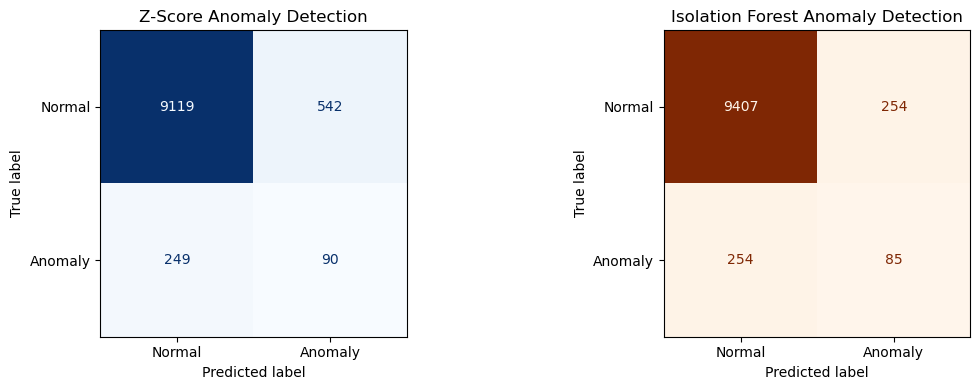

Phase 3 Done. Saved to SQLite.


In [26]:
# Confusion Matrix 对比图
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Z-Score
cm1 = confusion_matrix(df['failure'], df['zscore_anomaly'])
ConfusionMatrixDisplay(cm1, display_labels=['Normal', 'Anomaly']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Z-Score Anomaly Detection')

# Isolation Forest
cm2 = confusion_matrix(df['failure'], df['isoforest_anomaly'])
ConfusionMatrixDisplay(cm2, display_labels=['Normal', 'Anomaly']).plot(
    ax=axes[1], cmap='Oranges', colorbar=False)
axes[1].set_title('Isolation Forest Anomaly Detection')

plt.tight_layout()
plt.show()

# Save Phase 3 results to SQLite
conn = sqlite3.connect("machine_monitor.db")
df.to_sql("machine_data", conn, if_exists="replace", index=False)
print("Phase 3 Done. Saved to SQLite.")

In [27]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve,
                             precision_score, recall_score, f1_score)
import shap

feature_cols = [
    'air_temp', 'process_temp', 'rpm', 'torque', 'tool_wear',
    'temp_diff', 'power', 'tool_torque', 'tool_wear_index',
    'rpm_torque_ratio', 'rpm_rolling_mean', 'rpm_rolling_std',
    'torque_rolling_mean', 'torque_rolling_std', 'tool_wear_rolling_mean',
    'rpm_toolwear', 'temp_torque', 'power_toolwear',
    'rpm_change', 'torque_change', 'wear_change', 'wear_remaining',
    'hdf_risk', 'pwf_risk', 'osf_risk', 'Type'
]

X = df[feature_cols]
y = df['failure']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# ── Baseline (no balancing) ──
print("="*45)
print("BASELINE — NO BALANCING")
print("="*45)
lr_base = LogisticRegression(max_iter=1000, random_state=42)
rf_base = RandomForestClassifier(n_estimators=100, random_state=42)
lr_base.fit(X_train_scaled, y_train)
rf_base.fit(X_train_scaled, y_train)
print("\nLR Baseline:")
print(classification_report(y_test, lr_base.predict(X_test_scaled),
      target_names=['Normal','Failure'], digits=3))
print("RF Baseline:")
print(classification_report(y_test, rf_base.predict(X_test_scaled),
      target_names=['Normal','Failure'], digits=3))

# ── class_weight='balanced' (replaces SMOTE) ──
print("="*45)
print("WITH class_weight=balanced")
print("="*45)
lr = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
lr.fit(X_train_scaled, y_train)
rf.fit(X_train_scaled, y_train)
print("\nLR + balanced:")
print(classification_report(y_test, lr.predict(X_test_scaled),
      target_names=['Normal','Failure'], digits=3))
print("RF + balanced:")
print(classification_report(y_test, rf.predict(X_test_scaled),
      target_names=['Normal','Failure'], digits=3))

# ── Cross Validation ──
print("="*45)
print("CROSS VALIDATION (5-Fold F1)")
print("="*45)
lr_cv = cross_val_score(lr, X_train_scaled, y_train, cv=5, scoring='f1')
rf_cv = cross_val_score(rf, X_train_scaled, y_train, cv=5, scoring='f1')
print(f"LR  F1: {lr_cv.round(3)} | Mean: {lr_cv.mean():.3f}")
print(f"RF  F1: {rf_cv.round(3)} | Mean: {rf_cv.mean():.3f}")

# ── Threshold Analysis ──
print("="*45)
print("THRESHOLD ANALYSIS")
print("="*45)
lr_probs = lr.predict_proba(X_test_scaled)[:, 1]
rf_probs = rf.predict_proba(X_test_scaled)[:, 1]

results = []
for thresh in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    for name, probs in [('LR', lr_probs), ('RF', rf_probs)]:
        preds = (probs >= thresh).astype(int)
        results.append({
            'Model': name, 'Threshold': thresh,
            'Precision': round(precision_score(y_test, preds, zero_division=0), 3),
            'Recall':    round(recall_score(y_test, preds), 3),
            'F1':        round(f1_score(y_test, preds, zero_division=0), 3)
        })
print(pd.DataFrame(results).to_string(index=False))


BASELINE — NO BALANCING

LR Baseline:
              precision    recall  f1-score   support

      Normal      0.994     0.998     0.996      1932
     Failure      0.934     0.838     0.884        68

    accuracy                          0.993      2000
   macro avg      0.964     0.918     0.940      2000
weighted avg      0.992     0.993     0.992      2000

RF Baseline:
              precision    recall  f1-score   support

      Normal      0.994     0.999     0.997      1932
     Failure      0.983     0.838     0.905        68

    accuracy                          0.994      2000
   macro avg      0.989     0.919     0.951      2000
weighted avg      0.994     0.994     0.994      2000

WITH class_weight=balanced

LR + balanced:
              precision    recall  f1-score   support

      Normal      0.998     0.970     0.984      1932
     Failure      0.525     0.941     0.674        68

    accuracy                          0.969      2000
   macro avg      0.761     0.956 

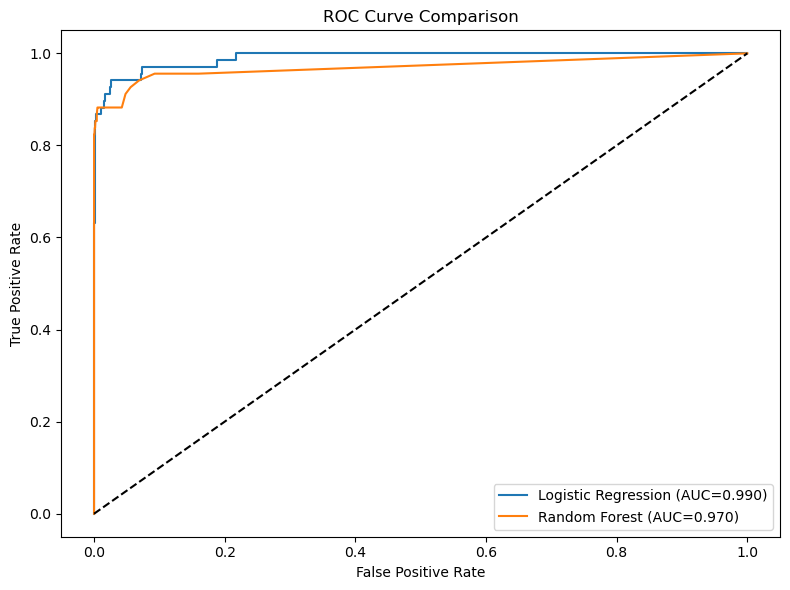

In [28]:
# ── ROC Curve ──
plt.figure(figsize=(8,6))
for name, probs in [('Logistic Regression', lr_probs), ('Random Forest', rf_probs)]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
plt.plot([0,1],[0,1],'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.tight_layout()
plt.show()


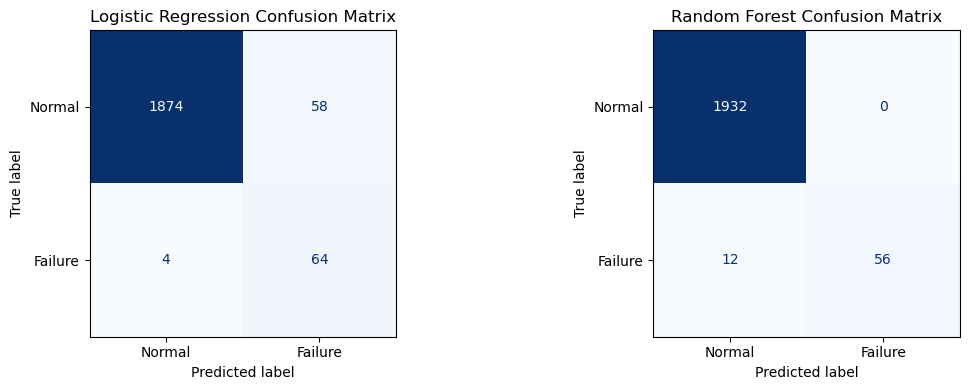

In [29]:
# ── 4.8 Confusion Matrix ──────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name, preds in [
    (axes[0], 'Logistic Regression', lr.predict(X_test_scaled)),
    (axes[1], 'Random Forest',       rf.predict(X_test_scaled))]:
    cm = confusion_matrix(y_test, preds)
    ConfusionMatrixDisplay(cm, display_labels=['Normal','Failure']).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name} Confusion Matrix')
plt.tight_layout()
plt.show()

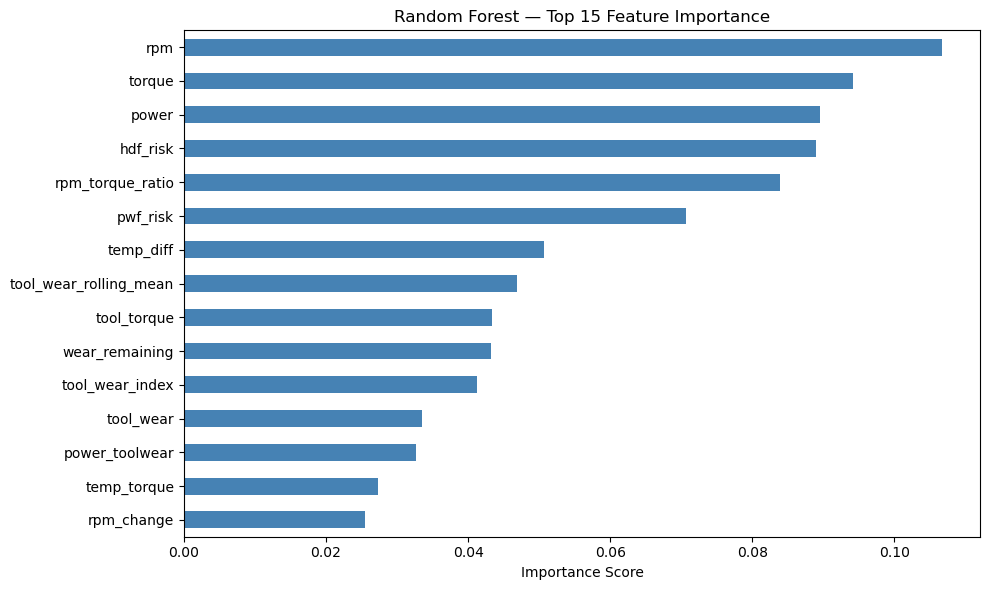

In [30]:
# ── 4.9 Feature Importance (RF) ───────────────
feat_imp = pd.Series(rf.feature_importances_, index=feature_cols)
feat_imp = feat_imp.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
feat_imp.plot(kind='barh', color='steelblue')
plt.gca().invert_yaxis()
plt.title('Random Forest — Top 15 Feature Importance')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

In [31]:
# ── Error Analysis ──
rf_preds = rf.predict(X_test_scaled)
X_test_copy = X_test.copy()
X_test_copy['actual']    = y_test.values
X_test_copy['predicted'] = rf_preds
X_test_copy['prob']      = rf_probs
fp = X_test_copy[(X_test_copy['actual']==0) & (X_test_copy['predicted']==1)]
fn = X_test_copy[(X_test_copy['actual']==1) & (X_test_copy['predicted']==0)]
print(f"\nFalse Positives (unnecessary maintenance): {len(fp)}")
print(f"False Negatives (missed failures):         {len(fn)}")


False Positives (unnecessary maintenance): 0
False Negatives (missed failures):         12


In [32]:
# ── Save to SQLite ──
df_out = X_test.copy()
df_out['actual_failure']  = y_test.values
df_out['pred_prob_lr']    = lr_probs
df_out['pred_prob_rf']    = rf_probs
df_out['pred_label_rf']   = rf_preds
df_out['model_agreement'] = (lr.predict(X_test_scaled) == rf_preds).astype(int)
df_out['risk_level']      = pd.cut(df_out['pred_prob_rf'],
                                    bins=[0, 0.4, 0.7, 1.0],
                                    labels=['Low','Medium','High'])

df_out['record_id'] = range(1, len(df_out) + 1)

conn = sqlite3.connect("machine_monitor.db")
df_out.to_sql("predictions", conn, if_exists="replace", index=False)
print("\nPhase 4 Done.")
print(df_out['risk_level'].value_counts())


Phase 4 Done.
risk_level
Low       314
High       52
Medium      8
Name: count, dtype: int64


In [33]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

df['record_id'] = range(1, len(df)+1)

conn = sqlite3.connect("machine_monitor.db")
df.to_sql("machine_data", conn, if_exists="replace", index=False)

# 1. machine_data.csv
df.to_csv("machine_data.csv", index=False)

# 2. predictions.csv（加 record_id）
df_pred = pd.read_sql("SELECT * FROM predictions", conn)
df_pred['record_id'] = range(1, len(df_pred)+1)
df_pred.to_csv("predictions.csv", index=False)

# 3. model_metrics.csv（自动从模型结果生成）
lr_preds_05 = (lr_probs >= 0.5).astype(int)
rf_preds_05 = (rf_probs >= 0.5).astype(int)

metrics = pd.DataFrame({
    'Model':     ['Logistic Regression', 'Random Forest'],
    'Precision': [
        round(precision_score(y_test, lr_preds_05, zero_division=0), 3),
        round(precision_score(y_test, rf_preds_05, zero_division=0), 3)
    ],
    'Recall': [
        round(recall_score(y_test, lr_preds_05), 3),
        round(recall_score(y_test, rf_preds_05), 3)
    ],
    'F1': [
        round(f1_score(y_test, lr_preds_05, zero_division=0), 3),
        round(f1_score(y_test, rf_preds_05, zero_division=0), 3)
    ],
    'AUC': [
        round(roc_auc_score(y_test, lr_probs), 3),
        round(roc_auc_score(y_test, rf_probs), 3)
    ]
})
metrics.to_csv("model_metrics.csv", index=False)
print(metrics)

# threshold_df
results = []
for thresh in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    for name, probs in [('LR', lr_probs), ('RF', rf_probs)]:
        preds = (probs >= thresh).astype(int)
        results.append({
            'Model': name, 'Threshold': thresh,
            'Precision': round(precision_score(y_test, preds, zero_division=0), 3),
            'Recall':    round(recall_score(y_test, preds), 3),
            'F1':        round(f1_score(y_test, preds, zero_division=0), 3)
        })
threshold_df = pd.DataFrame(results)
threshold_df.to_csv("threshold_analysis.csv", index=False)

# feature importance
feat_imp_df = pd.DataFrame({
    'Feature':    feature_cols,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False).head(15)
feat_imp_df.to_csv("feature_importance.csv", index=False)

print("threshold_analysis.csv exported!")
print("feature_importance.csv exported!")
print(threshold_df)

                 Model  Precision  Recall     F1   AUC
0  Logistic Regression      0.525   0.941  0.674  0.99
1        Random Forest      1.000   0.824  0.903  0.97
threshold_analysis.csv exported!
feature_importance.csv exported!
   Model  Threshold  Precision  Recall     F1
0     LR        0.2      0.201   0.971  0.333
1     RF        0.2      0.879   0.853  0.866
2     LR        0.3      0.288   0.971  0.444
3     RF        0.3      0.935   0.853  0.892
4     LR        0.4      0.368   0.941  0.529
5     RF        0.4      0.935   0.853  0.892
6     LR        0.5      0.525   0.941  0.674
7     RF        0.5      1.000   0.824  0.903
8     LR        0.6      0.678   0.897  0.772
9     RF        0.6      1.000   0.809  0.894
10    LR        0.7      0.756   0.868  0.808
11    RF        0.7      1.000   0.765  0.867



=== Risk Level Distribution ===
risk_level
Low         1938
High          32
Critical      20
Medium        10
Name: count, dtype: int64

=== Score Stats by Level ===
             count  mean   std   min   25%   50%   75%   max
risk_level                                                  
Critical      20.0  90.0   0.0  90.0  90.0  90.0  90.0  90.0
High          32.0  75.0   5.1  70.0  70.0  75.5  80.0  80.0
Low         1938.0   1.1   3.5   0.0   0.0   0.0   0.0  27.0
Medium        10.0  47.5  10.1  35.0  39.0  49.5  54.5  63.0

Computing SHAP values (may take ~30 seconds)...


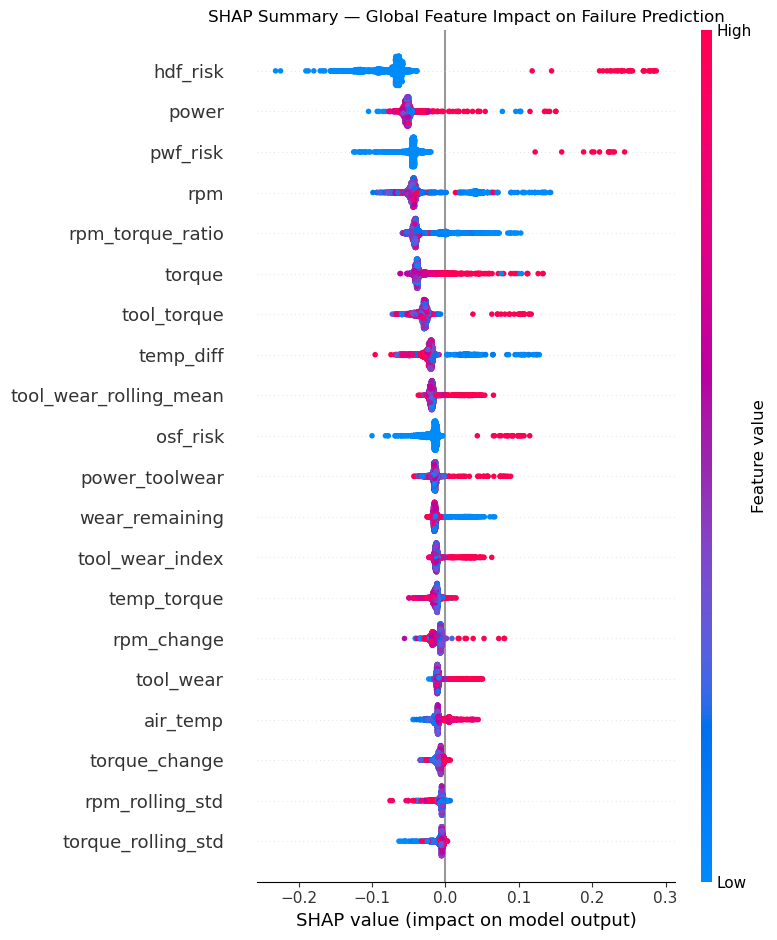

Saved: shap_summary.png


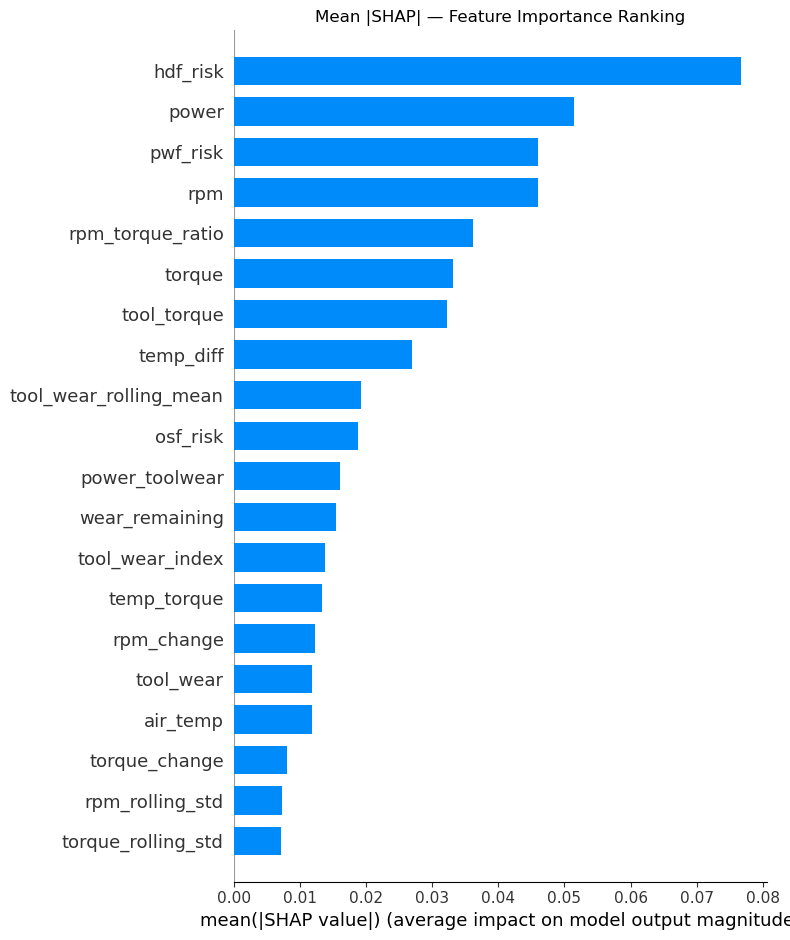

Saved: shap_bar.png


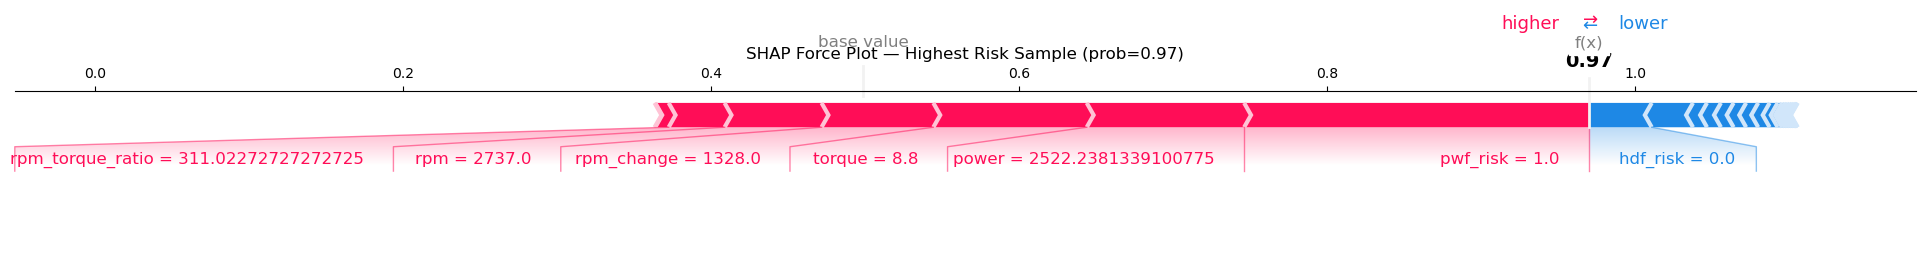

Saved: shap_force.png
Saved: shap_importance.json

=== Sample High-Risk Records ===
    record_id  pred_prob  risk_score risk_level                                  action                                                 shap_explanation
17         18       0.84          80       High      Schedule inspection within 4 hours               hdf_risk(↑0.279) | rpm(↑0.114) | temp_diff(↑0.103)
21         22       0.97          90   Critical  Immediate shutdown inspection required                pwf_risk(↑0.224) | power(↑0.102) | torque(↑0.100)
40         41       0.95          90   Critical  Immediate shutdown inspection required               hdf_risk(↑0.241) | rpm(↑0.130) | temp_diff(↑0.113)
43         44       0.87          80       High      Schedule inspection within 4 hours                pwf_risk(↑0.188) | power(↑0.139) | torque(↑0.112)
64         65       0.84          80       High      Schedule inspection within 4 hours  tool_torque(↑0.114) | osf_risk(↑0.102) | power_toolwear(↑0.081

In [34]:
import pandas as pd
import numpy as np
import sqlite3
import shap
import matplotlib.pyplot as plt
from datetime import datetime


# ══════════════════════════════════════════
# PART 1 — RISK ENGINE (已更新為 Decision Layer 精簡版)
# ══════════════════════════════════════════

HIGH_PROB_OVERRIDE = 0.90
HIGH_RISK_THRESHOLD = 65

import pandas as pd
import numpy as np
import sqlite3
import shap
import matplotlib.pyplot as plt
from datetime import datetime


# ══════════════════════════════════════════
# PART 1 — RISK ENGINE (已更新為 Decision Layer 精簡版)
# ══════════════════════════════════════════

HIGH_RISK_THRESHOLD = 65

# Probability Safety Floor — a risk-policy table, not an "override".
# Maps predicted failure probability to the MINIMUM risk_score a record
# is allowed to receive, regardless of how few domain/anomaly flags it
# triggered. Rule Engine + Anomaly signals can still push the score
# ABOVE this floor (e.g. a 69% record with multiple flags can still
# reach Critical), but they can never push it below.
PROBABILITY_SAFETY_FLOOR = [
    (0.90, 90),
    (0.80, 80),
    (0.70, 70),
    (0.50, 50),
]

def compute_risk_score(prob, row):
    """
    Multi-signal risk fusion.

    Combines:
    1. ML prediction probability
    2. Rule-based engineering knowledge
    3. Statistical anomaly detection

    Returns:
        score (0-100),
        risk level,
        maintenance action,
        human-readable reasons.
    """
    points = 0
    reasons = []
    override_applied = False

    # -------------------------------
    # Layer 1 — ML Probability (0–50)
    # -------------------------------
    ml_pts = round(prob * 50)
    points += ml_pts

    if prob >= 0.65:
        reasons.append(f"High failure probability ({prob:.0%})")
    elif prob >= 0.35:
        reasons.append(f"Elevated failure probability ({prob:.0%})")

    # -------------------------------
    # Layer 2 — Domain Knowledge (0–30)
    # -------------------------------
    if row.get("hdf_risk", 0):
        points += 15
        reasons.append(
            "Heat dissipation failure condition (low temp_diff + low rpm)"
        )

    if row.get("pwf_risk", 0):
        points += 10
        reasons.append(
            "Power failure condition (power out of safe range)"
        )

    if row.get("osf_risk", 0):
        points += 15
        reasons.append(
            "Overstrain failure condition (tool_torque threshold exceeded)"
        )

    # -------------------------------
    # Layer 3 — Anomaly Detection (0–20)
    # -------------------------------
    if row.get("isoforest_anomaly", 0):
        points += 12
        reasons.append("Isolation Forest anomaly detected")

    if row.get("zscore_anomaly", 0):
        points += 8
        reasons.append("Z-score anomaly detected")

    points = min(points, 100)

    # -------------------------------
    # Probability Safety Floor (risk-policy enforcement, not an "override")
    # -------------------------------
    # Rationale: a high ML failure probability (e.g. 88%) must never end up
    # with a LOWER risk score than a lower-probability record (e.g. 71%)
    # just because the lower one triggered more domain/anomaly flags.
    # Failure Probability sets a MINIMUM guaranteed score; Rule Engine and
    # Anomaly Detection signals can still push the score ABOVE that floor
    # (e.g. a 69% record with several flags can still reach Critical) —
    # they just can't push it below. This preserves the value of the
    # multi-signal fusion while removing the reversed-ranking contradiction.
    floor = 0
    for prob_threshold, floor_value in PROBABILITY_SAFETY_FLOOR:
        if prob >= prob_threshold:
            floor = floor_value
            break

    if points < floor:
        original_points = points
        points = floor
        override_applied = True  # kept as-is: existing decision_log/dashboard schema reads this column
        reasons.append(
            f"Probability safety floor applied: score adjusted from {original_points} to {floor} "
            f"per risk policy, since predicted failure probability ({prob:.0%}) guarantees "
            f"a minimum risk level regardless of rule/anomaly signal count"
        )

    # -------------------------------
    # Final Risk Classification
    # -------------------------------
    if points >= 85:
        level = "Critical"
        action = "Immediate shutdown inspection required"

    elif points >= HIGH_RISK_THRESHOLD:
        level = "High"
        action = "Schedule inspection within 4 hours"

    elif points >= 35:
        level = "Medium"
        action = "Monitor closely, inspect within 24 hours"

    else:
        level = "Low"
        action = "Normal operation"

    return {
        "risk_score": points,
        "risk_level": level,
        "action": action,
        "reasons": " | ".join(reasons) if reasons else "No risk signals",
        "prob": round(float(prob), 4),
        "override_applied": override_applied,
        "timestamp": datetime.now().isoformat()
    }


# Apply risk engine to all test rows (保持原樣)
flag_cols = ['hdf_risk', 'pwf_risk', 'osf_risk', 'isoforest_anomaly', 'zscore_anomaly']
X_test_flags = X_test.copy()
for col in flag_cols:
    X_test_flags[col] = df.loc[X_test.index, col].values

risk_results = []
for prob, (_, row) in zip(rf_probs, X_test_flags.iterrows()):
    risk_results.append(compute_risk_score(prob, row))

risk_df = pd.DataFrame(risk_results)
print("\n=== Risk Level Distribution ===")
print(risk_df['risk_level'].value_counts())
print("\n=== Score Stats by Level ===")
print(risk_df.groupby('risk_level')['risk_score'].describe().round(1))


# ══════════════════════════════════════════
# PART 2 — SHAP EXPLAINABILITY (保持原樣)
# ══════════════════════════════════════════

print("\nComputing SHAP values (may take ~30 seconds)...")
explainer   = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test_scaled)

# For binary classification: index [1] = failure class
shap_vals_failure = shap_values[1]

# --- Plot 1: Global summary ---
plt.figure()
shap.summary_plot(
    shap_vals_failure, X_test,
    feature_names=feature_cols,
    show=False
)
plt.title("SHAP Summary — Global Feature Impact on Failure Prediction")
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=150)
plt.show()
print("Saved: shap_summary.png")

# --- Plot 2: Bar chart ---
plt.figure()
shap.summary_plot(
    shap_vals_failure, X_test,
    feature_names=feature_cols,
    plot_type="bar",
    show=False
)
plt.title("Mean |SHAP| — Feature Importance Ranking")
plt.tight_layout()
plt.savefig("shap_bar.png", dpi=150)
plt.show()
print("Saved: shap_bar.png")

# --- Plot 3: Force plot for highest-risk prediction ---
top_risk_idx = risk_df['risk_score'].idxmax()

shap.force_plot(
    explainer.expected_value[1],
    shap_vals_failure[top_risk_idx],
    X_test.iloc[top_risk_idx],
    feature_names=feature_cols,
    matplotlib=True,
    show=False
)
plt.title(f"SHAP Force Plot — Highest Risk Sample (prob={rf_probs[top_risk_idx]:.2f})")
plt.tight_layout()
plt.savefig("shap_force.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: shap_force.png")

# --- Save mean |SHAP| importance as JSON for the dynamic dashboard chart ---
import json
import os

mean_abs_shap = np.abs(shap_vals_failure).mean(axis=0)
shap_importance = sorted(
    [{"feature": f, "importance": round(float(v), 5)} for f, v in zip(feature_cols, mean_abs_shap)],
    key=lambda x: x["importance"],
    reverse=True
)

shap_importance_payload = {
    "model": "Random Forest",
    "trained_at": datetime.now().isoformat(timespec='seconds'),
    "total_predictions": int(len(X_test_scaled)),
    "features": shap_importance
}

# Save next to model_metrics.csv so app.py can find it via the same base path
SHAP_IMPORTANCE_JSON = os.path.join(
    os.path.dirname(os.path.abspath("model_metrics.csv")), "shap_importance.json"
)
with open("shap_importance.json", "w") as f:
    json.dump(shap_importance_payload, f, indent=2)

print("Saved: shap_importance.json")

# --- Human-readable top-3 reasons per prediction ---
def get_top_shap_reasons(shap_row, feature_names, n=3):
    pairs = sorted(zip(feature_names, shap_row), key=lambda x: abs(x[1]), reverse=True)
    return ' | '.join(
        f"{feat}({'↑' if val>0 else '↓'}{abs(val):.3f})"
        for feat, val in pairs[:n]
    )

shap_reasons = [
    get_top_shap_reasons(row, feature_cols)
    for row in shap_vals_failure
]


# ══════════════════════════════════════════
# PART 3 — BUILD FINAL decision_log TABLE (已同步 override_applied 欄位)
# ══════════════════════════════════════════

decision_log = X_test.copy().reset_index(drop=True)
decision_log['actual_failure'] = y_test.values
decision_log['pred_prob']      = rf_probs

# Attach risk engine output (已將 override_applied 加密納入 logging)
for key in [
    'risk_score',
    'risk_level',
    'action',
    'reasons',
    'override_applied',
    'timestamp'
]:
    decision_log[key] = [r[key] for r in risk_results]

# Attach SHAP top-3 reasons (保持原樣)
decision_log['shap_explanation'] = shap_reasons

# Attach anomaly flags from original df (保持原樣)
for col in flag_cols:
    decision_log[col] = df.loc[X_test.index, col].values

# Alert status (starts as OPEN for High/Critical) (保持原樣)
decision_log['alert_status'] = decision_log['risk_level'].apply(
    lambda x: 'OPEN' if x in ['High', 'Critical'] else 'OK'
)

# Unique ID for each record (Flask API will use this) (保持原樣)
decision_log['record_id'] = range(1, len(decision_log) + 1)

print("\n=== Sample High-Risk Records ===")
high_risk = decision_log[decision_log['risk_level'].isin(['High', 'Critical'])]
print(high_risk[['record_id', 'pred_prob', 'risk_score', 'risk_level',
                  'action', 'shap_explanation']].head(5).to_string())

# Save to SQLite — two tables (保持原樣)
conn = sqlite3.connect("machine_monitor.db")

# Table 1: full decision log (Flask API reads from here)
decision_log.to_sql("decision_log", conn, if_exists="replace", index=False)

# Table 2: SHAP values table (dashboard reads for visualisation)
shap_df = pd.DataFrame(shap_vals_failure, columns=feature_cols)
shap_df['record_id']       = range(1, len(shap_df) + 1)
shap_df['top_feature']     = shap_df[feature_cols].abs().idxmax(axis=1)
shap_df['top_shap_value']  = shap_df[feature_cols].abs().max(axis=1).round(4)
shap_df.to_sql("shap_values", conn, if_exists="replace", index=False)

conn.close()

print("\n=== Layer 4 Complete ===")
print(f"decision_log rows : {len(decision_log)}")
print(f"shap_values rows  : {len(shap_df)}")
print(f"Open alerts       : {(decision_log['alert_status']=='OPEN').sum()}")
print("Tables saved: decision_log, shap_values")
print("Images saved: shap_summary.png, shap_bar.png, shap_force.png")
print("\nNext step: Layer 5 — Flask API reads from decision_log table")

In [35]:
import os
print(os.getcwd())

C:\Users\limli\Inti Folder\FYP


In [36]:
df_out["pred_lr"] = (df_out["pred_prob_lr"] >= 0.5).astype(int)
df_out["pred_rf"] = (df_out["pred_prob_rf"] >= 0.5).astype(int)

print(
    ((df_out["pred_lr"] == 1) & (df_out["pred_rf"] == 0)).sum()
)

print(
    ((df_out["pred_lr"] == 0) & (df_out["pred_rf"] == 1)).sum()
)

66
0


In [5]:
import os, sqlite3, pandas as pd
from sklearn.metrics import average_precision_score

DB = r"C:\Users\limli\Inti Folder\FYP\machine_monitor.db"
assert os.path.exists(DB), f"找不到数据库文件: {DB}"

conn = sqlite3.connect(f"file:{DB}?mode=ro", uri=True)   # 只读模式，不会修改数据库
df = pd.read_sql("SELECT actual_failure, pred_prob_lr, pred_prob_rf FROM predictions", conn)
conn.close()

print("rows:", len(df), "| failures:", int(df.actual_failure.sum()))
print("LR PR-AUC:", round(average_precision_score(df.actual_failure, df.pred_prob_lr), 3))
print("RF PR-AUC:", round(average_precision_score(df.actual_failure, df.pred_prob_rf), 3))

rows: 2000 | failures: 68
LR PR-AUC: 0.916
RF PR-AUC: 0.904
